Plots the Gillespie simulations which appear in figure 1

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from gillespie import gillespie, analytic_sol
import matplotlib as mpl

plt.rcParams['axes.linewidth'] = 2.0  # Sets thicker axis borders globally
plt.rcParams['xtick.major.width'] = 2.0  # Sets thicker x-ticks globally
plt.rcParams['ytick.major.width'] = 2.0  # Sets thicker y-ticks globally
mpl.rcParams['axes.spines.top'] = False
mpl.rcParams['axes.spines.right'] = False

np.random.seed(527)
# Colorblind-safe pool-size colors, shared across the low- and high-load panels.
c_small = '#009E73'  # N = 100
c_large = '#CC79A7'  # N = 300

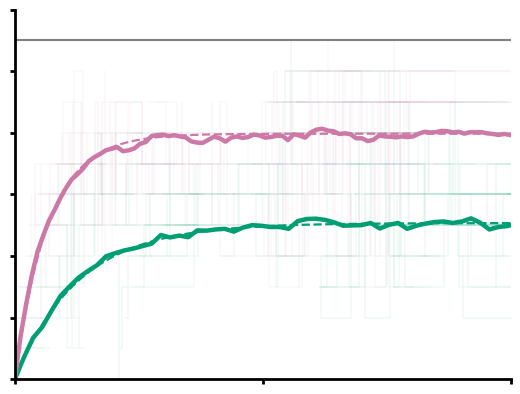

In [45]:
p0 = np.array([11,0,100,0.0015,0.0001,3,8,9.5]) #0 = low pool size, low load
N0,N_a0,t0,t_ave0 = gillespie(100,60,p0)
n0,ti0 = analytic_sol(p0,t_max=12000)

p1 = np.array([11,0,300,0.0015,0.0001,3,8,9.5]) #1 = large pool size, low load
N1,N_a1,t1,t_ave1 = gillespie(100,60,p1)
n1,ti1 = analytic_sol(p1,t_max=12000)

#Plotting:

plt.step(t0[0:5,:],N0[0:5,:],marker='',color=c_small,linewidth=0.35,alpha=0.18)
plt.step(t1[0:5,:],N1[0:5,:],marker='',color=c_large,linewidth=0.35,alpha=0.18)

plt.plot(ti0,n0,lw=1.6,linestyle='--',color=c_small)
plt.plot(ti1,n1,lw=1.6,linestyle='--',color=c_large)

plt.plot(t_ave0,N_a0,color=c_small,lw=3.2,label='Small Pool')
plt.plot(t_ave1,N_a1,color=c_large,lw=3.2,label='Large Pool')


plt.xlim(0,12000)
plt.ylim(0,12)
plt.yticks([0,2,4,6,8,10,12],[])
plt.xticks([0,6000,12000],[])
plt.axhline(11,c='gray')

plt.savefig('../figure-output/gillespie-lowload.pdf', dpi=600)

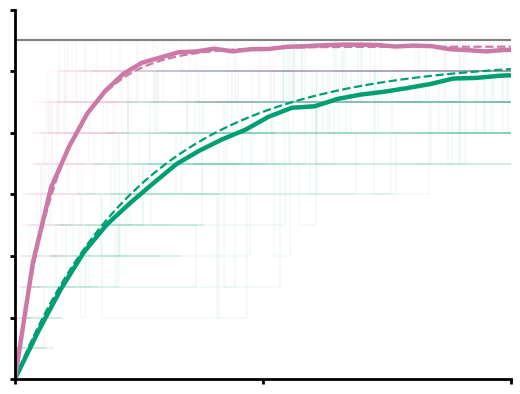

In [47]:
p2 = np.array([11,0,100,0.0015,0.0001,3,8,12.5]) #2 = low pool size, high load
N2,N_a2,t2,t_ave2 = gillespie(100,20,p2)
n2,ti2 = analytic_sol(p2,t_max=12000)

p3 = np.array([11,0,300,0.0015,0.0001,3,8,12.5]) #3 = large pool size, high load
N3,N_a3,t3,t_ave3 = gillespie(100,20,p3)
n3,ti3 = analytic_sol(p3,t_max=12000)

#Plotting:

plt.step(t2[0:25,:],N2[0:25,:],marker='',color=c_small,linewidth=0.35,alpha=0.18)
plt.step(t3[0:25,:],N3[0:25,:],marker='',color=c_large,linewidth=0.35,alpha=0.18)

plt.plot(ti2,n2,c=c_small,lw=1.6,linestyle='--',label='Analytical Result')
plt.plot(ti3,n3,c=c_large,lw=1.6,linestyle='--')

plt.plot(t_ave2,N_a2,color=c_small,lw=3.2,label='Small Pool')
plt.plot(t_ave3,N_a3,color=c_large,lw=3.2,label='Large Pool')


plt.xlim(0,12000)
plt.ylim(0,12)
plt.yticks([0,2,4,6,8,10,12],[])
plt.xticks([0,6000,12000],[])
plt.axhline(11,c='gray')

plt.savefig('../figure-output/gillespie-highload.pdf', dpi=600)